# Çok Modlu Ürün Kategori Sınıflandırma — 4. Ek Görevler

Görsel model için **Grad-CAM** ısı haritaları ve **Gradio** ile basit bir demo. Hiçbir model yeniden eğitilmiyor ve 2. notebook'ta kaydedilen görsel model Drive'dan yükleniyor.

## Kurulum

In [31]:
# kütüphaneler
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
import kagglehub

# Drive bağlantısı ve sabitler
from google.colab import drive
drive.mount("/content/drive")
CIKTI = "/content/drive/MyDrive/onproje"
TOHUM = 42
tf.keras.utils.set_random_seed(TOHUM)

# görsellerin bulunduğu klasör
veri_yolu = kagglehub.dataset_download("paramaggarwal/fashion-product-images-small")

# 1. notebook'ta hazırlanan veri; yalnızca test kümesi lazım
veri = pd.read_csv(f"{CIKTI}/hazir_veri.csv", dtype={"id": str})
test = veri[veri["kume"] == "test"].reset_index(drop=True)

# sınıf sırası (görsel modelin 0–19 numaraları)
with open(f"{CIKTI}/siniflar.json") as f:
    SINIFLAR = json.load(f)

# 2. notebook'ta eğitilen en iyi görsel model (39. tur)
model = keras.models.load_model(f"{CIKTI}/gorsel_asama2.keras")
model.summary()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using Colab cache for faster access to the 'fashion-product-images-small' dataset.


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ veri_artirma (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gomme (GlobalAveragePooling2D)  │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 20)             │        25,620 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,093,153 (27.06 MB)

 Trainable params: 1,508,980 (5.76 MB)

 Non-trainable params: 2,566,211 (9.79 MB)

 Optimizer params: 3,017,962 (11.51 MB)

## 1. Grad-CAM
### 1.1 Modelin bu notebook'ta doğru çalıştığının kontrolü

Ürün:   Lino Perros Women Sequin Green Wallet
Gerçek: Wallets
Tahmin: Wallets | olasılık: 0.998


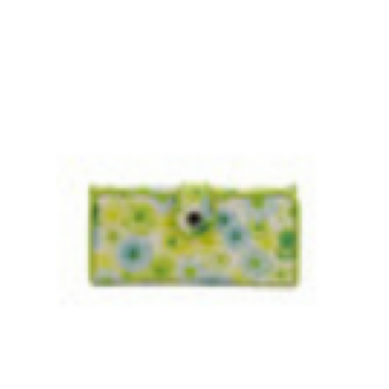

In [32]:
BOYUT = 128

def gorsel_yukle(yol):
    # 2. notebook'taki hazırlığı kullandım
    g = tf.io.read_file(yol)
    g = tf.io.decode_image(g, channels=3, expand_animations=False)
    g = tf.cast(g, tf.float32)
    g = 255.0 - tf.image.resize_with_pad(255.0 - g, BOYUT, BOYUT)
    return g

# test kümesinden ilk ürünü denedim
ornek = test.iloc[89]
g = gorsel_yukle(f"{veri_yolu}/images/{ornek['id']}.jpg")

# model paket beklediği için başa bir boyut ekledim
olasilik = model.predict(tf.expand_dims(g, 0), verbose=0)[0]
tahmin_no = olasilik.argmax()

print("Ürün:  ", ornek["productDisplayName"])
print("Gerçek:", ornek["articleType"])
print("Tahmin:", SINIFLAR[tahmin_no], "| olasılık:", round(float(olasilik[tahmin_no]), 3))

plt.imshow(g.numpy().astype("uint8"))
plt.axis("off")
plt.show()


### 1.2 Grad-CAM fonksiyonu ve çelişkili bir örnek

Grad-CAM tahmini: Wallets | olasılık: 0.998


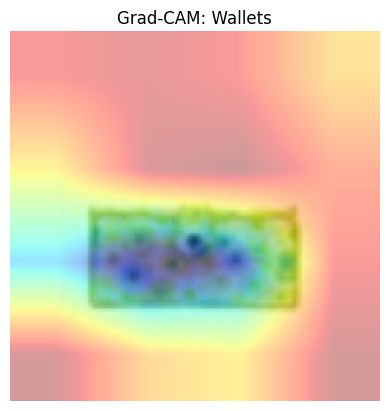

In [33]:
# modelin parçalarını ayrı ayrı aldım
govde = model.get_layer("efficientnetb0")
gomme_katmani = model.get_layer("gomme")
cikis_katmani = model.get_layer("dense")       # 20 sınıf
W, b = cikis_katmani.kernel, cikis_katmani.bias

def grad_cam(g, sinif_no=None):
    x = tf.expand_dims(g, 0)
    with tf.GradientTape() as tape:
        A = govde(x, training=False)            # özellik haritaları
        tape.watch(A)
        h = gomme_katmani(A)                    # (1,1280)
        logit = tf.matmul(h, W) + b             # softmax öncesi sınıf puanları (1,20)
        if sinif_no is None:
            sinif_no = int(tf.argmax(logit[0]))  # sınıf verilmezse modelin tahmini
        puan = logit[:, sinif_no]
    grad = tape.gradient(puan, A)               # gradyan (1,4,4,1280)
    agirlik = tf.reduce_mean(grad, axis=(0, 1, 2))          # her özelliğin önemi (1280)
    harita = tf.reduce_sum(A[0] * agirlik, axis=-1)          #  ağırlıklı toplam (4,4)
    harita = tf.nn.relu(harita)                               #    yalnızca olumlu katkı
    harita = harita / (tf.reduce_max(harita) + 1e-8)          #    0–1 arasına ölçekle
    return harita.numpy(), sinif_no, tf.nn.softmax(logit[0]).numpy()

# elle hesapladığım olasılıklar modelinkiyle aynı mı?
harita, sinif_no, olas = grad_cam(g)
print("Grad-CAM tahmini:", SINIFLAR[sinif_no], "| olasılık:", round(float(olas[sinif_no]), 3))

#  haritayı 128x128'e büyütüp görselin üstüne koydum
buyuk = tf.image.resize(harita[..., None], (BOYUT, BOYUT)).numpy()[..., 0]
plt.imshow(g.numpy().astype("uint8"))
plt.imshow(buyuk, cmap="jet", alpha=0.4)
plt.title(f"Grad-CAM: {SINIFLAR[sinif_no]}")
plt.axis("off")
plt.savefig(f"{CIKTI}/gradcam_cuzdan.png", dpi=150, bbox_inches="tight")
plt.show()


Denemeler sırasında çelişkili bir örnek buldum: cüzdan görselinde model doğru tahmin yapmasına
rağmen ısı haritası ürünün kendisini değil çevresindeki boş alanı gösteriyor.

Bu örneği, yöntemin sınırlılığını göstermek için bilerek tuttum.


### 1.3 Doğru tahminler (6 farklı sınıf)

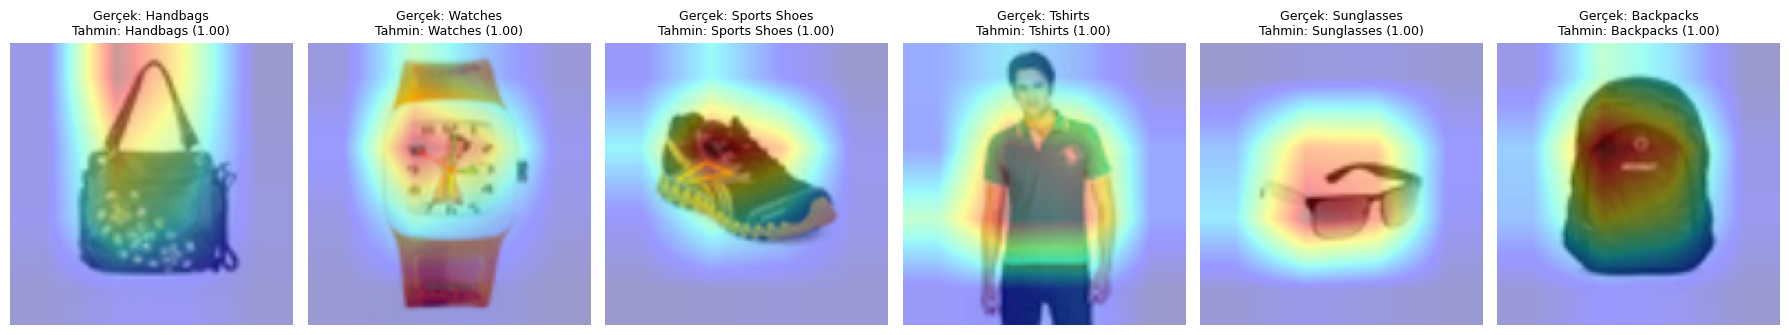

In [34]:
def cam_ciz(eksen, satir, sinif_no=None):
    g = gorsel_yukle(f"{veri_yolu}/images/{satir['id']}.jpg")
    harita, sinif_no, olas = grad_cam(g, sinif_no)
    buyuk = tf.image.resize(harita[..., None], (BOYUT, BOYUT)).numpy()[..., 0]
    eksen.imshow(g.numpy().astype("uint8"))
    eksen.imshow(buyuk, cmap="jet", alpha=0.4)
    eksen.set_title(f"Gerçek: {satir['articleType']}\nTahmin: {SINIFLAR[sinif_no]} ({olas[sinif_no]:.2f})", fontsize=9)
    eksen.axis("off")

# farklı sınıflardan birer test ürünü seçtim
secilen = ["Handbags", "Watches", "Sports Shoes", "Tshirts", "Sunglasses", "Backpacks"]
ornekler = [test[test["articleType"] == s].iloc[0] for s in secilen]

fig, eksenler = plt.subplots(1, 6, figsize=(18, 4))
for eksen, satir in zip(eksenler, ornekler):
    cam_ciz(eksen, satir)
plt.tight_layout()
plt.savefig(f"{CIKTI}/gradcam_dogru.png", dpi=150, bbox_inches="tight")

plt.show()


Genel bir çelişki olmadığını çoğunda kırmızılık mantıklı yerlerde olduğunu görüp tespit ettim

### 1.4 Yanlış tahminler (en emin olunan 6 hata)

Görsel modelin test hatası: 396


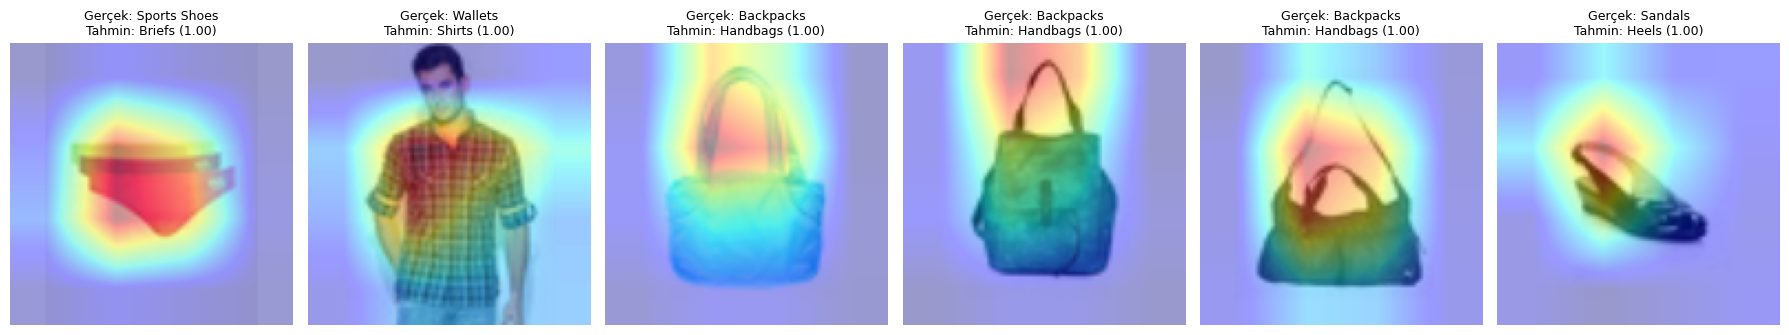

In [35]:
# görsel modelin test olasılıkları 02'de kaydedittiğim  test tablosundan aldım
gorsel_olas = np.load(f"{CIKTI}/gorsel_olasilik_test.npy")
y_test = test["articleType"].map({s: i for i, s in enumerate(SINIFLAR)}).values

tahmin = gorsel_olas.argmax(1)
yanlislar = test[tahmin != y_test].copy()
yanlislar["guven"] = gorsel_olas[tahmin != y_test].max(1)
yanlislar = yanlislar.sort_values("guven", ascending=False)   # en emin olunan yanlışları önce aldım
print("Görsel modelin test hatası:", len(yanlislar))

fig, eksenler = plt.subplots(1, 6, figsize=(18, 4))
for eksen, (_, satir) in zip(eksenler, yanlislar.head(6).iterrows()):
    cam_ciz(eksen, satir)          # harita modelin yanlış tahmini için çiziliyor
plt.tight_layout()
plt.savefig(f"{CIKTI}/gradcam_yanlis.png", dpi=150)
plt.show()


En emin olunan 6 hatanın 2'si etiket hatası , 3'ü saplı sırt
çantası (model Handbags kararını sapa bakarak veriyor), 1'i hem sandalet hem topuklu bir ürün.
Yani hataların çoğu model hatası değil, etiket hatası ya da belirsiz kategori.


peki en çok karışan shoes sınıfı neden yok? onları baz alarak ayrıca bakmak istedim


### 1.5 Casual ↔ Sports karışması
En emin olunan 6 hatanın hiçbiri ayakkabı karışması değil oysa 3. notebook'ta en sık hata Casual <-> Sports ayakkabıydı. Bu yüzden bu karışmaya ayrıca baktım ve  her ürün için hem tahmin edilen hem gerçek sınıfın haritasını çizdim.

Casual ↔ Sports hata sayısı: 111


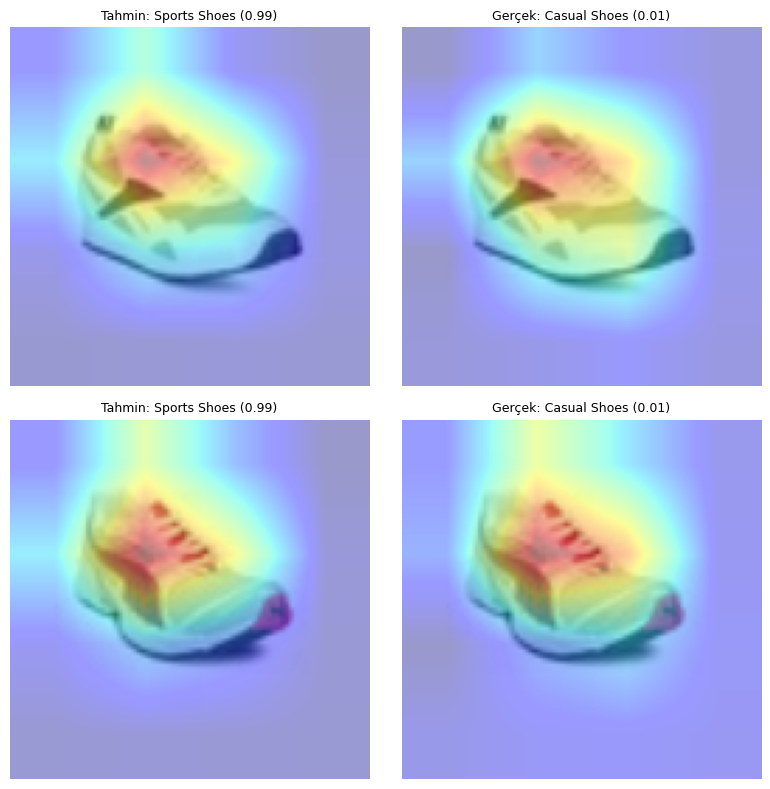

In [36]:

yanlislar["tahmin"] = [SINIFLAR[tahmin[i]] for i in yanlislar.index]

# yalnızca Casual / Sports karışmaları
casual_sports = ((yanlislar["articleType"] == "Casual Shoes") & (yanlislar["tahmin"] == "Sports Shoes")) | \
                ((yanlislar["articleType"] == "Sports Shoes") & (yanlislar["tahmin"] == "Casual Shoes"))
ayakkabi = yanlislar[casual_sports].head(2)
print("Casual ↔ Sports hata sayısı:", casual_sports.sum())

def cam_goster(eksen, g, sinif_adi, baslik):
    harita, _, olas = grad_cam(g, SINIFLAR.index(sinif_adi))     # haritayı istenen sınıf için hesaplattım
    buyuk = tf.image.resize(harita[..., None], (BOYUT, BOYUT)).numpy()[..., 0]
    eksen.imshow(g.numpy().astype("uint8"))
    eksen.imshow(buyuk, cmap="jet", alpha=0.4)
    eksen.set_title(f"{baslik}: {sinif_adi} ({olas[SINIFLAR.index(sinif_adi)]:.2f})", fontsize=9)
    eksen.axis("off")

fig, eksenler = plt.subplots(2, 2, figsize=(8, 8))
for satir_eksen, (_, satir) in zip(eksenler, ayakkabi.iterrows()):
    g = gorsel_yukle(f"{veri_yolu}/images/{satir['id']}.jpg")
    cam_goster(satir_eksen[0], g, satir["tahmin"], "Tahmin")         # sol: modelin dediği
    cam_goster(satir_eksen[1], g, satir["articleType"], "Gerçek")    # sağ: olması gereken
plt.tight_layout()
plt.savefig(f"{CIKTI}/gradcam_ayakkabi.png", dpi=150)
plt.show()


Casual / Sports karışmalarında iki sınıfın haritası da ayakkabının aynı bölgesini gösteriyor.
Model bu sınıfları ince stil ayrıntılarıyla ayırmaya çalışıyor ama düşük çözünürlük bunu zorlaştırıyor.


## 2. Gradio demosu
### 2.1 Tahmin fonksiyonu
Demoda geç füzyonu kullandım: En iyi sonucu veren yöntem o ve iki model ayrı çalıştığı için yalnızca görselle ya da yalnızca adla da tahmin yapılabiliyor.

In [37]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from PIL import Image

# metin modeli: 1. notebook'taki en iyi ayar (char TF-IDF 2–5 + LR, C = 10), yalnızca train ile
train = veri[veri["kume"] == "train"].reset_index(drop=True)
sinif_no = {s: i for i, s in enumerate(SINIFLAR)}
vek = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5))
X_train = vek.fit_transform(train["productDisplayName"])
metin_modeli = LogisticRegression(C=10, max_iter=2000)
metin_modeli.fit(X_train, train["articleType"].map(sinif_no).values)   # 0–19, görselle aynı sıra

W_METIN = 0.55   # 3. notebook'ta doğrulama kümesinde seçilen geç füzyon ağırlığı

def gorsel_olasilik(gorsel_dizi):
    # 2. notebook'taki hazırlığın aynısı (128x128, beyaz dolgu)
    g = tf.cast(gorsel_dizi[..., :3], tf.float32)          # PNG'lerde 4. kanal varsa at
    g = 255.0 - tf.image.resize_with_pad(255.0 - g, BOYUT, BOYUT)
    return model.predict(tf.expand_dims(g, 0), verbose=0)[0]

def metin_olasilik(urun_adi):
    return metin_modeli.predict_proba(vek.transform([urun_adi]))[0]

def birlesik_tahmin(gorsel_dizi, urun_adi):
    ad_var = bool(urun_adi and urun_adi.strip())
    if gorsel_dizi is None and not ad_var:
        return None                                        # hiçbir girdi yok
    if gorsel_dizi is None:
        return metin_olasilik(urun_adi)                    # yalnızca ad → metin modeli
    if not ad_var:
        return gorsel_olasilik(gorsel_dizi)                # yalnızca görsel → görsel model
    return W_METIN * metin_olasilik(urun_adi) + (1 - W_METIN) * gorsel_olasilik(gorsel_dizi)   # geç füzyon

# deneme: aynı test ürünü için üç durum
ornek = test.iloc[5]
gorsel_dizi = np.array(Image.open(f"{veri_yolu}/images/{ornek['id']}.jpg").convert("RGB"))
print("Ürün:", ornek["productDisplayName"], "| Gerçek:", ornek["articleType"])
for ad, p in [("Yalnızca görsel", birlesik_tahmin(gorsel_dizi, "")),
              ("Yalnızca ad",     birlesik_tahmin(None, ornek["productDisplayName"])),
              ("Geç füzyon",      birlesik_tahmin(gorsel_dizi, ornek["productDisplayName"]))]:
    en_iyi = p.argsort()[::-1][:2]
    print(f"  {ad:<16}", " | ".join(f"{SINIFLAR[i]} {p[i]:.3f}" for i in en_iyi))


Ürün: Grendha Women Kall Ad Black Flats | Gerçek: Heels
  Yalnızca görsel  Heels 0.901 | Sandals 0.099
  Yalnızca ad      Heels 0.976 | Flip Flops 0.003
  Geç füzyon       Heels 0.942 | Sandals 0.044


### 2.2 Gradio kurulumu


In [38]:
!pip install -q gradio


### 2.3 Arayüz

In [39]:
import gradio as gr
print("gradio", gr.__version__)      # requirements.txt için sürümü öğrendim

def demo_tahmin(gorsel, urun_adi):
    p = birlesik_tahmin(gorsel, urun_adi)
    if p is None:
        return {}
    return {SINIFLAR[i]: float(p[i]) for i in range(len(SINIFLAR))}   # sınıf → olasılık

# demoda hazır örnek olarak 3 test ürünü
ornekler = [[f"{veri_yolu}/images/{r['id']}.jpg", r["productDisplayName"]]
            for _, r in test.sample(3, random_state=TOHUM).iterrows()]

arayuz = gr.Interface(
    fn=demo_tahmin,
    inputs=[gr.Image(type="numpy", label="Ürün görseli (boş bırakılırsa yalnızca ad kullanılır)"),
            gr.Textbox(label="Ürün adı (boş bırakılırsa yalnızca görsel kullanılır)")],
    outputs=gr.Label(num_top_classes=5, label="Tahmin"),
    title="Çok Modlu Ürün Kategori Sınıflandırma",
    description="Görsel + ad: geç füzyon (w = 0,55) · yalnızca görsel: görsel model · yalnızca ad: metin modeli",
    examples=ornekler,
)
arayuz.launch()


gradio 6.29.0
It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://26bd85b0a4d869d5ee.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Demo üç durumda çalışıyor: yalnızca görsel (görsel model), yalnızca ad (metin modeli), ikisi birlikte (geç füzyon, w = 0,55). Bir tişört görseliyle denedim: Görsel tek başına Tshirts %92, "Gini Jony Girls Printed White Top" adı tek başına Tops %100 dedi. İkisi birlikte verilince sonuç Tops %58, Tshirts %42 çıktı. İki model çelişince geç füzyon ağırlığa göre karar veriyor.

### 2.4 Demo için örnek görseller
Sunumda kullanmak için test kümesinden farklı durumları gösteren 6 ürün seçip Drive'a kopyaladım.

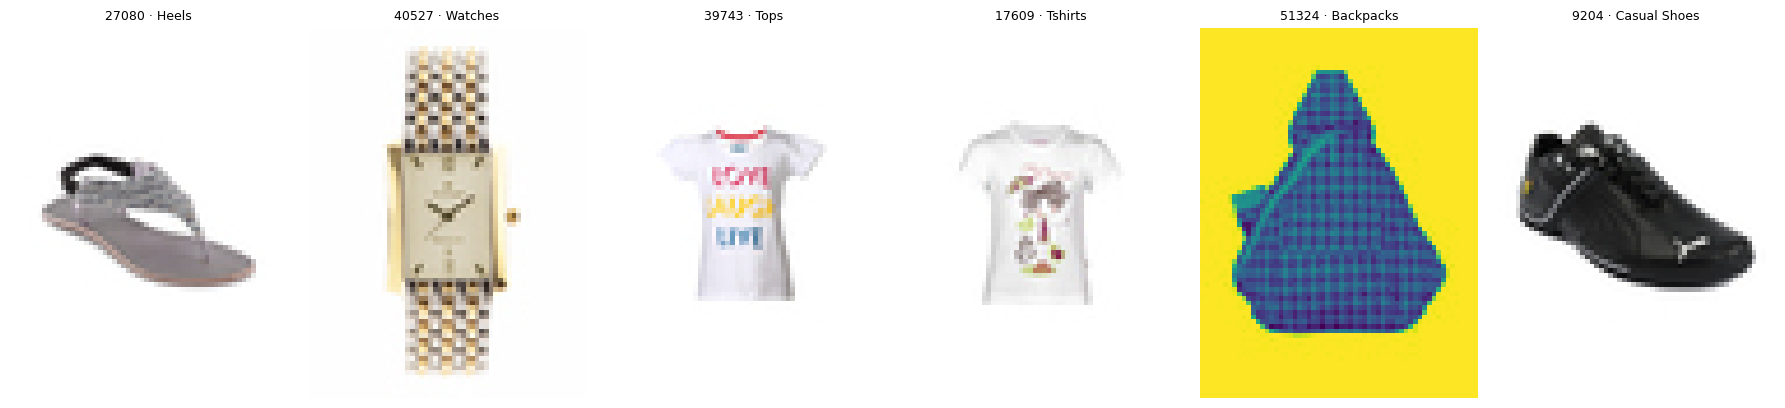

   id  articleType                                               productDisplayName
27080        Heels                                       Catwalk Women Silver Flats
40527      Watches                                        Titan Men Gold Dial Watch
39743         Tops                                Gini Jony Girls Printed White Top
17609      Tshirts                             Doodle Girls Raindrops White Tshirts
51324    Backpacks Wildcraft Unisex Black & Grey Houndstooth Print One-Shoulder Bag
 9204 Casual Shoes                  Puma Men Future Cat Remix SF Black Casual Shoes


In [40]:
import shutil, os

demo_idleri = ["39743", "17609", "27080", "9204", "51324", "40527"]
demo_urunler = test[test["id"].isin(demo_idleri)]

# Drive'a kopyaladım ki  bilgisayara indirip arayüzde kullanabilmek için
DEMO = f"{CIKTI}/demo_gorseller"
os.makedirs(DEMO, exist_ok=True)

fig, eksenler = plt.subplots(1, 6, figsize=(18, 4))
for eksen, (_, r) in zip(eksenler, demo_urunler.iterrows()):
    yol = f"{veri_yolu}/images/{r['id']}.jpg"
    shutil.copy(yol, f"{DEMO}/{r['id']}.jpg")
    eksen.imshow(Image.open(yol))
    eksen.set_title(f"{r['id']} · {r['articleType']}", fontsize=9)
    eksen.axis("off")
plt.tight_layout()
plt.show()

# adları kopyala-yapıştır için yazdır
print(demo_urunler[["id", "articleType", "productDisplayName"]].to_string(index=False))
